# Land Cover Classification — RAM-Optimised Continuation
**Strategy**: never hold all pixel arrays in RAM simultaneously.
- All pixel data is saved to `.npz` files on disk immediately after extraction.
- Training uses **incremental / chunk-based** fitting.
- The U-Net `LazyPatchDataset` reads GeoTIFFs **one tile at a time** from disk — stores only index tuples in RAM.
- Peak RAM target: **< 3.5 GB**.

---
## Cell 1 — Imports & Paths

In [1]:
import os, gc
import numpy as np
import rasterio
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay
import joblib
import warnings
warnings.filterwarnings('ignore')

DATA_FOLDER  = r'S2_ML_Dataset_V2'
MODEL_FOLDER = r'models'
CACHE_FOLDER = r'cache'   # npz pixel caches go here
for d in (MODEL_FOLDER, CACHE_FOLDER):
    os.makedirs(d, exist_ok=True)

CLASS_NAMES  = ['Greenery', 'Sand', 'Water', 'Cement']
CLASS_LABELS = [1, 2, 3, 4]

TRAIN_LOCS = [
    'BaharyaOasis','EasternDesert','FarafraOasis','KhargaOasis',
    'LibyanBorder','SinaiDesert','WhiteDesert',
    'AssiutFarms','BeheiraNileDelta','DakhlaOasis','DamietaFarms',
    'HawaraFayoum','MiniaFarms','NileDelta','SohagFarms',
    'WadiNatrun','ZagazigFarms',
    'AlexandriaPort','CairoDowntown','CairoUniv','FayoumFarms',
    'GizaPlateau','HelwanIndustrial','MansouraCity','NaserCity',
    'AbuSimbelDesert','BardawilLake','GreatBitterLake','GulfSuez',
    'ManzalaLake','NasserLake','RedSeaHurghada','SaddElAly','SuezCanal',
]
VAL_LOCS = [
    'IconicTower','QattaraDepression','KarnakLuxor','SiwaOasis',
    'PortSaidCity','ZagazigCity','GulfAqaba','MariutLake',
]
TEST_LOCS = [
    'QenaFarms','TantaCity','NileCairo','SuezCity',
    'WadiElGemal','WadiRum','QarunLake','TimsahLake',
]

CMAP = mcolors.ListedColormap(['black','darkgreen','yellow','darkblue','gray'])
NORM = mcolors.BoundaryNorm([0,1,2,3,4,5], CMAP.N)
print('setup done.')

setup done.


---
## Cell 2 — Core Functions

In [2]:
def compute_indices(bands):
    B2=bands[1].astype(np.float32); B3=bands[2].astype(np.float32)
    B4=bands[3].astype(np.float32); B8=bands[7].astype(np.float32)
    B8A=bands[8].astype(np.float32); B11=bands[10].astype(np.float32)
    e=1e-10
    NDVI     = (B8-B4)/(B8+B4+e)
    MOISTURE = (B8A-B11)/(B8A+B11+e)
    NDWI     = (B3-B8)/(B3+B8+e)
    NDBI     = (B11-B8)/(B11+B8+e)
    BSI      = ((B11+B4)-(B8+B2))/((B11+B4)+(B8+B2)+e)
    return np.stack([NDVI,MOISTURE,NDWI,NDBI,BSI], axis=0)


def load_image_and_mask(location_name):
    img_path  = os.path.join(DATA_FOLDER, location_name+'_12band.tif')
    mask_path = os.path.join(DATA_FOLDER, location_name+'_mask_ESRI.tif')
    with rasterio.open(img_path) as f:
        bands = f.read().astype(np.float32)
    with rasterio.open(mask_path) as f:
        mask = f.read(1)
    H=min(bands.shape[1],mask.shape[0]); W=min(bands.shape[2],mask.shape[1])
    bands=bands[:,:H,:W]; mask=mask[:H,:W]
    bands=np.clip(bands/10000.0,0,1)
    bands=np.nan_to_num(bands,nan=0.0,posinf=0.0,neginf=0.0)
    indices=compute_indices(bands)
    indices=np.nan_to_num(indices,nan=0.0,posinf=0.0,neginf=0.0)
    return np.concatenate([bands,indices],axis=0).astype(np.float32), mask


def compute_miou(true_labels, pred_labels):
    iou_scores={}
    for c in CLASS_LABELS:
        tp=np.sum((pred_labels==c)&(true_labels==c))
        fp=np.sum((pred_labels==c)&(true_labels!=c))
        fn=np.sum((pred_labels!=c)&(true_labels==c))
        iou_scores[c]=tp/(tp+fp+fn+1e-10)
    return iou_scores, float(np.mean(list(iou_scores.values())))

print('functions ready.')

functions ready.


---
## Cell 3 — Extract & Cache Pixels to Disk
Reads **one GeoTIFF at a time**, saves at most `MAX_PX_PER_CLASS` pixels per class
to a small `.npz`, then immediately frees RAM. Re-run skips existing caches.

In [3]:
# 34 train locs × 4 classes × 5000 px = 680 000 pixels total ≈ 175 MB on disk, ~45 MB in RAM
MAX_PX_PER_CLASS = 5000

def cache_location(loc, max_per_class=MAX_PX_PER_CLASS):
    out_path = os.path.join(CACHE_FOLDER, loc+'.npz')
    if os.path.exists(out_path):
        return True   # already cached
    try:
        features, mask = load_image_and_mask(loc)
        X=features.reshape(17,-1).T; y=mask.flatten()
        del features, mask; gc.collect()
        keep=y>0; X,y=X[keep],y[keep]
        clean=~np.isnan(X).any(axis=1); X,y=X[clean],y[clean]
        rng=np.random.RandomState(42)
        Xo,yo=[],[]
        for c in CLASS_LABELS:
            idx=np.where(y==c)[0]
            if len(idx)==0: continue
            chosen=rng.choice(idx,min(len(idx),max_per_class),replace=False)
            Xo.append(X[chosen]); yo.append(y[chosen])
        if Xo:
            np.savez_compressed(out_path,
                X=np.vstack(Xo).astype(np.float32),
                y=np.concatenate(yo).astype(np.uint8))
        del X,y,Xo,yo; gc.collect()
        return False
    except Exception as ex:
        print(f'  SKIP {loc}: {ex}'); return False

all_locs = TRAIN_LOCS+VAL_LOCS+TEST_LOCS
print(f'caching {len(all_locs)} locations…')
for loc in all_locs:
    already = cache_location(loc)
    print(f'  {loc:<25} {"(already cached)" if already else "saved"}')
print('done.')

caching 50 locations…
  BaharyaOasis              saved
  EasternDesert             saved
  FarafraOasis              saved
  KhargaOasis               saved
  LibyanBorder              saved
  SinaiDesert               saved
  WhiteDesert               saved
  AssiutFarms               saved
  BeheiraNileDelta          saved
  DakhlaOasis               saved
  DamietaFarms              saved
  HawaraFayoum              saved
  MiniaFarms                saved
  NileDelta                 saved
  SohagFarms                saved
  WadiNatrun                saved
  ZagazigFarms              saved
  AlexandriaPort            saved
  CairoDowntown             saved
  CairoUniv                 saved
  FayoumFarms               saved
  GizaPlateau               saved
  HelwanIndustrial          saved
  MansouraCity              saved
  NaserCity                 saved
  AbuSimbelDesert           saved
  BardawilLake              saved
  GreatBitterLake           saved
  GulfSuez                

---
## Cell 4 — Fit Scaler Incrementally
`partial_fit` processes one `.npz` at a time — never more than ~2 MB in RAM.

In [4]:
SCALER_PATH = os.path.join(MODEL_FOLDER,'scaler.pkl')
if os.path.exists(SCALER_PATH):
    print('loading saved scaler…'); scaler=joblib.load(SCALER_PATH)
else:
    print('fitting scaler incrementally…')
    scaler=StandardScaler()
    for loc in TRAIN_LOCS:
        path=os.path.join(CACHE_FOLDER,loc+'.npz')
        if not os.path.exists(path): continue
        data=np.load(path)
        scaler.partial_fit(data['X'].astype(np.float64))
        del data; gc.collect()
    joblib.dump(scaler,SCALER_PATH)
    print('scaler saved.')

loading saved scaler…


---
## Cell 5 — Classical Approach: Random Forest (warm_start incremental)

`warm_start=True` lets us call `.fit()` repeatedly, each time adding
`TREES_PER_BATCH` new trees trained on one location's pixels.
Old data is discarded after each batch — only the grown forest stays in RAM.

In [5]:
from sklearn.ensemble import RandomForestClassifier

RF_PATH = os.path.join(MODEL_FOLDER,'rf_model.pkl')
TREES_PER_BATCH = 6   # 34 locs × 6 = 204 trees total

if os.path.exists(RF_PATH):
    print('loading saved RF…'); rf=joblib.load(RF_PATH)
else:
    print('training RF incrementally…')
    rf=RandomForestClassifier(
        n_estimators=TREES_PER_BATCH, max_depth=20,
        min_samples_leaf=10, max_features='sqrt',
        class_weight='balanced', warm_start=True,
        n_jobs=-1, random_state=42,
    )
    total_trees=0
    for i,loc in enumerate(TRAIN_LOCS):
        path=os.path.join(CACHE_FOLDER,loc+'.npz')
        if not os.path.exists(path): continue
        data=np.load(path)
        X=scaler.transform(data['X'].astype(np.float64)).astype(np.float32)
        y=data['y'].astype(int)
        del data; gc.collect()
        total_trees+=TREES_PER_BATCH
        rf.n_estimators=total_trees
        rf.fit(X,y)
        del X,y; gc.collect()
        print(f'  [{i+1:2d}/{len(TRAIN_LOCS)}] {loc:<25} trees={total_trees}')
    joblib.dump(rf,RF_PATH)
    print(f'RF saved — {rf.n_estimators} trees.')

loading saved RF…


---
## Cell 6 — RF Evaluation & Feature Importance

[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.2s
[Parallel(n_jobs=12)]: Done 176 tasks      | elapsed:    0.3s
[Parallel(n_jobs=12)]: Done 200 out of 200 | elapsed:    0.3s finished
[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 176 tasks      | elapsed:    0.1s
[Parallel(n_jobs=12)]: Done 200 out of 200 | elapsed:    0.1s finished
[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 176 tasks      | elapsed:    0.1s
[Parallel(n_jobs=12)]: Done 200 out of 200 | elapsed:    0.1s finished
[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Do


───────────────────────────────────────────────────────
  Random Forest | Validation
───────────────────────────────────────────────────────


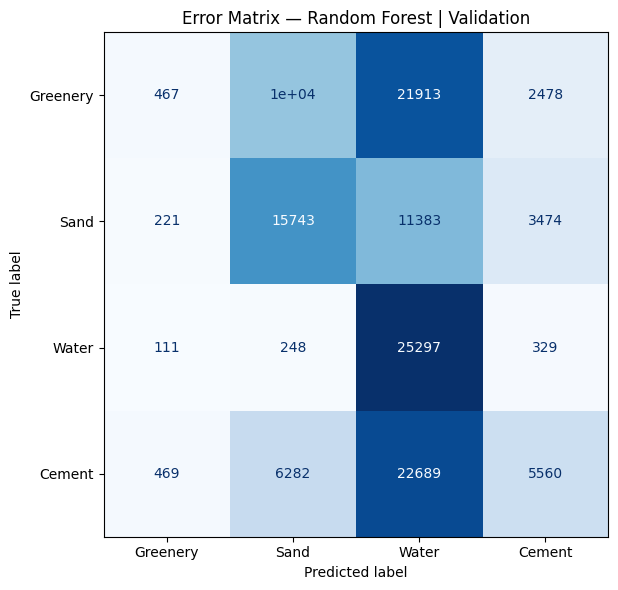

Errors of omission:
  Greenery    : 0.9867
  Sand        : 0.4892
  Water       : 0.0265
  Cement      : 0.8411
Errors of commission:
  Greenery    : 0.6317
  Sand        : 0.5143
  Water       : 0.6888
  Cement      : 0.5304

mIoU = 0.1970
  Greenery    : 0.0130
  Sand        : 0.3315
  Water       : 0.3086
  Cement      : 0.1347
              precision    recall  f1-score   support

    Greenery       0.37      0.01      0.03     35000
        Sand       0.49      0.51      0.50     30821
       Water       0.31      0.97      0.47     25985
      Cement       0.47      0.16      0.24     35000

    accuracy                           0.37    126806
   macro avg       0.41      0.41      0.31    126806
weighted avg       0.41      0.37      0.29    126806



[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 176 tasks      | elapsed:    0.1s
[Parallel(n_jobs=12)]: Done 200 out of 200 | elapsed:    0.1s finished
[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 176 tasks      | elapsed:    0.1s
[Parallel(n_jobs=12)]: Done 200 out of 200 | elapsed:    0.1s finished
[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 176 tasks      | elapsed:    0.1s
[Parallel(n_jobs=12)]: Done 200 out of 200 | elapsed:    0.1s finished
[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Do


───────────────────────────────────────────────────────
  Random Forest | Test
───────────────────────────────────────────────────────


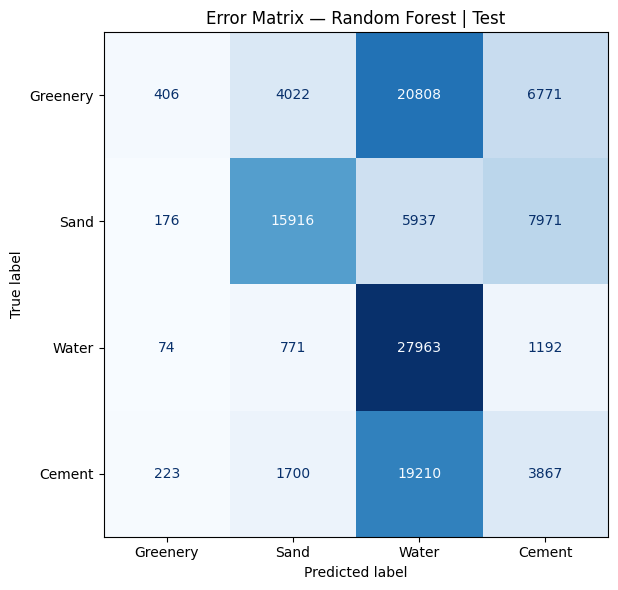

Errors of omission:
  Greenery    : 0.9873
  Sand        : 0.4695
  Water       : 0.0679
  Cement      : 0.8453
Errors of commission:
  Greenery    : 0.5381
  Sand        : 0.2897
  Water       : 0.6217
  Cement      : 0.8047

mIoU = 0.2278
  Greenery    : 0.0125
  Sand        : 0.4361
  Water       : 0.3682
  Cement      : 0.0945
              precision    recall  f1-score   support

    Greenery       0.46      0.01      0.02     32007
        Sand       0.71      0.53      0.61     30000
       Water       0.38      0.93      0.54     30000
      Cement       0.20      0.15      0.17     25000

    accuracy                           0.41    117007
   macro avg       0.44      0.41      0.34    117007
weighted avg       0.45      0.41      0.34    117007



In [6]:
def evaluate_on_locations(model_name, predict_fn, location_list, split_name):
    """Load one npz at a time, collect predictions, free RAM, then report."""
    all_pred,all_true=[],[]
    for loc in location_list:
        path=os.path.join(CACHE_FOLDER,loc+'.npz')
        if not os.path.exists(path): continue
        data=np.load(path)
        X=scaler.transform(data['X'].astype(np.float64)).astype(np.float32)
        y=data['y'].astype(int)
        np.nan_to_num(X,nan=0.0,copy=False)
        pred=predict_fn(X)
        all_pred.append(pred); all_true.append(y)
        del data,X,y,pred; gc.collect()

    all_pred=np.concatenate(all_pred); all_true=np.concatenate(all_true)
    print(f'\n{"─"*55}\n  {model_name} | {split_name}\n{"─"*55}')
    cm=confusion_matrix(all_true,all_pred,labels=CLASS_LABELS)
    fig,ax=plt.subplots(figsize=(7,6))
    ConfusionMatrixDisplay(cm,display_labels=CLASS_NAMES).plot(ax=ax,cmap='Blues',colorbar=False)
    ax.set_title(f'Error Matrix — {model_name} | {split_name}')
    plt.tight_layout()
    plt.savefig(os.path.join(MODEL_FOLDER,
        f'cm_{model_name.lower().replace(" ","_")}_{split_name.lower()}.png'),dpi=150)
    plt.show()
    print('Errors of omission:')
    for i,name in enumerate(CLASS_NAMES):
        print(f'  {name:<12}: {1-cm[i,i]/(cm[i].sum()+1e-10):.4f}')
    print('Errors of commission:')
    for i,name in enumerate(CLASS_NAMES):
        print(f'  {name:<12}: {1-cm[i,i]/(cm[:,i].sum()+1e-10):.4f}')
    iou_dict,miou=compute_miou(all_true,all_pred)
    print(f'\nmIoU = {miou:.4f}')
    for label,name in zip(CLASS_LABELS,CLASS_NAMES):
        print(f'  {name:<12}: {iou_dict[label]:.4f}')
    print(classification_report(all_true,all_pred,target_names=CLASS_NAMES,labels=CLASS_LABELS))
    del all_pred,all_true; gc.collect()
    return iou_dict,miou

rf_val_iou,  rf_val_miou  = evaluate_on_locations('Random Forest',rf.predict,VAL_LOCS, 'Validation')
rf_test_iou, rf_test_miou = evaluate_on_locations('Random Forest',rf.predict,TEST_LOCS,'Test')

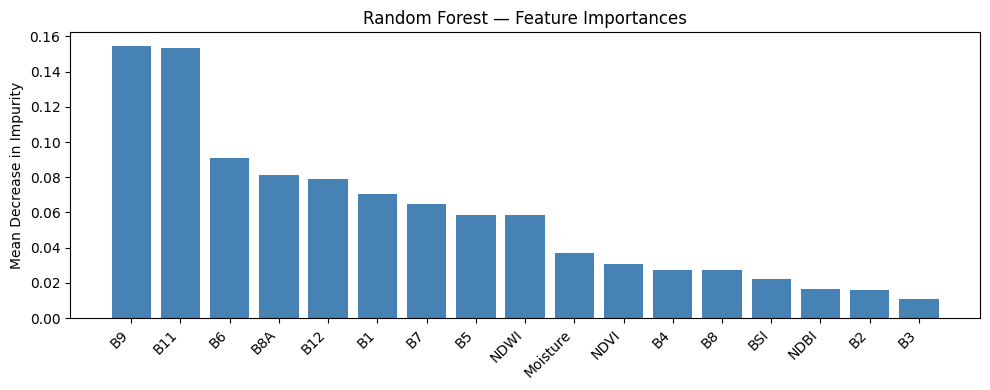

In [7]:
feature_names=['B1','B2','B3','B4','B5','B6','B7','B8','B8A','B9','B11','B12',
               'NDVI','Moisture','NDWI','NDBI','BSI']
imp=rf.feature_importances_; order=np.argsort(imp)[::-1]
fig,ax=plt.subplots(figsize=(10,4))
ax.bar(range(len(imp)),imp[order],color='steelblue')
ax.set_xticks(range(len(imp))); ax.set_xticklabels([feature_names[i] for i in order],rotation=45,ha='right')
ax.set_ylabel('Mean Decrease in Impurity'); ax.set_title('Random Forest — Feature Importances')
plt.tight_layout(); plt.savefig(os.path.join(MODEL_FOLDER,'rf_feature_importance.png'),dpi=150); plt.show()

[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.2s
[Parallel(n_jobs=12)]: Done 176 tasks      | elapsed:    1.1s
[Parallel(n_jobs=12)]: Done 200 out of 200 | elapsed:    1.3s finished


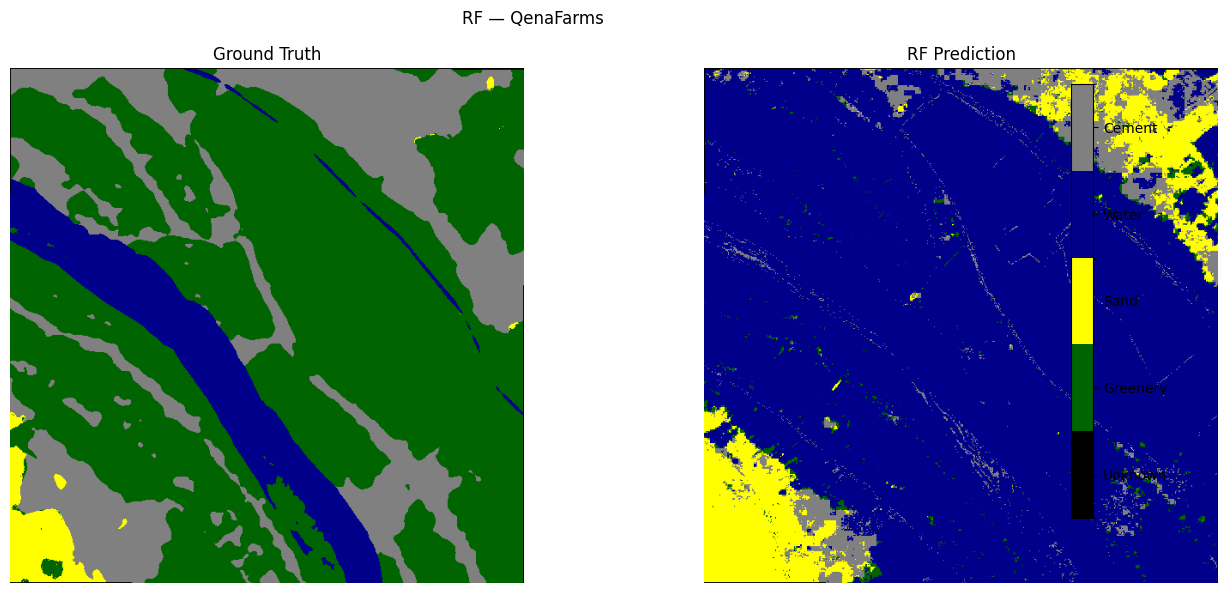

[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.2s
[Parallel(n_jobs=12)]: Done 176 tasks      | elapsed:    1.0s
[Parallel(n_jobs=12)]: Done 200 out of 200 | elapsed:    1.1s finished


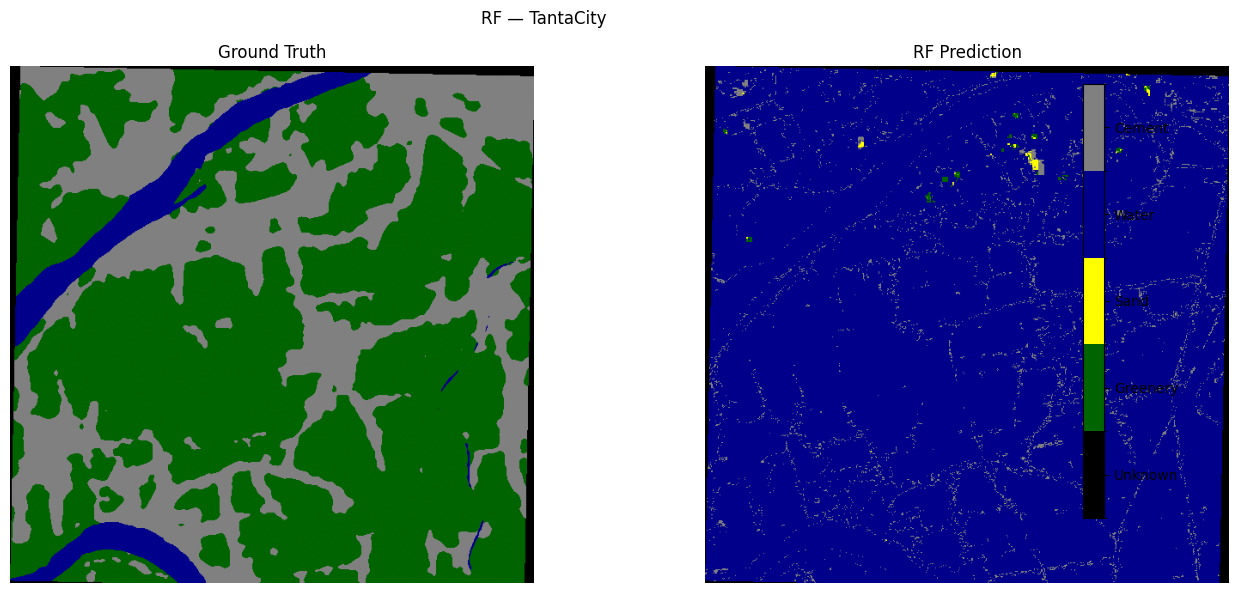

[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.2s
[Parallel(n_jobs=12)]: Done 176 tasks      | elapsed:    1.2s
[Parallel(n_jobs=12)]: Done 200 out of 200 | elapsed:    1.4s finished


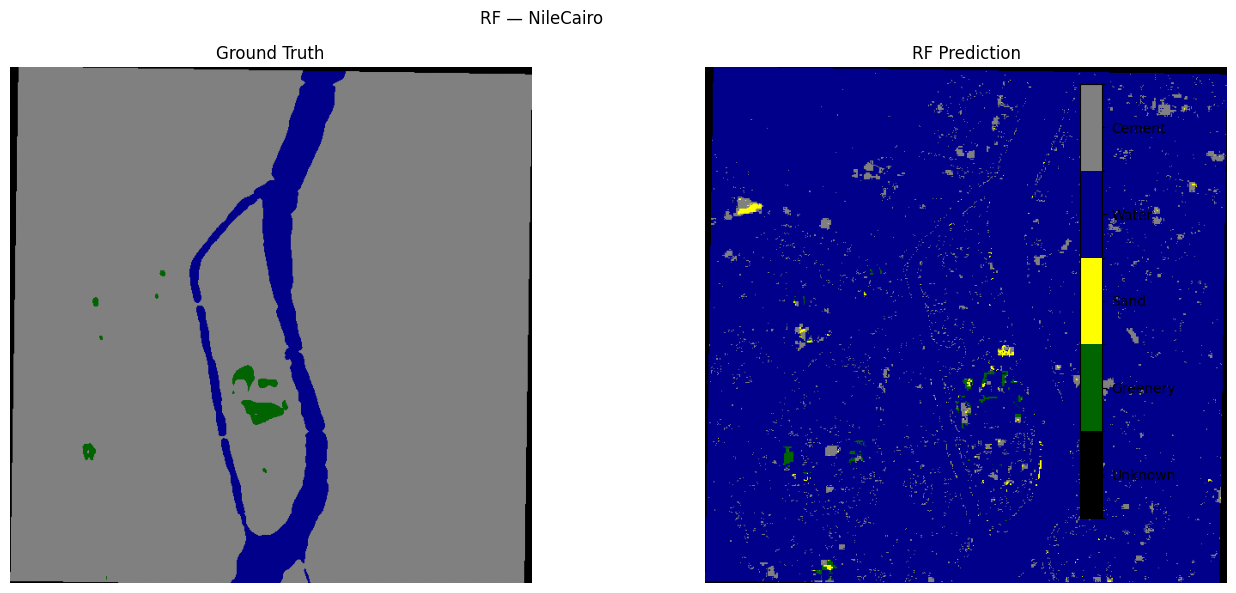

In [8]:
def make_thematic_map(location_name, predict_fn, title_prefix):
    """Predict full image one location at a time and immediately free RAM."""
    features,mask=load_image_and_mask(location_name)
    H,W=mask.shape
    X_img=features.reshape(17,-1).T
    del features; gc.collect()
    X_s=scaler.transform(X_img.astype(np.float64)).astype(np.float32)
    np.nan_to_num(X_s,nan=0.0,copy=False)
    del X_img; gc.collect()
    pred=predict_fn(X_s).reshape(H,W)
    del X_s; gc.collect()
    pred[mask==0]=0
    fig,axes=plt.subplots(1,2,figsize=(14,6))
    axes[0].imshow(mask,cmap=CMAP,norm=NORM); axes[0].set_title('Ground Truth'); axes[0].axis('off')
    im=axes[1].imshow(pred,cmap=CMAP,norm=NORM); axes[1].set_title(f'{title_prefix} Prediction'); axes[1].axis('off')
    cbar=plt.colorbar(im,ax=axes,ticks=[0.5,1.5,2.5,3.5,4.5],fraction=0.02,pad=0.04)
    cbar.ax.set_yticklabels(['Unknown','Greenery','Sand','Water','Cement'])
    plt.suptitle(f'{title_prefix} — {location_name}'); plt.tight_layout()
    plt.savefig(os.path.join(MODEL_FOLDER,f'{title_prefix.lower()}_{location_name}.png'),dpi=150); plt.show()
    del pred,mask; gc.collect()

for loc in TEST_LOCS[:3]:
    make_thematic_map(loc, rf.predict, 'RF')

---
## Cell 7 — U-Net Setup

In [9]:
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader

DEVICE     = 'cuda' if torch.cuda.is_available() else 'cpu'
PATCH_SIZE = 128
OVERLAP    = 16
BATCH_SIZE = 8     # small batch → less VRAM
EPOCHS     = 40
LR         = 3e-4
NUM_CLASSES= 5
N_FEATURES = 17
UNET_PATH  = os.path.join(MODEL_FOLDER,'unet_best.pth')

print(f'Device: {DEVICE}')
if DEVICE=='cuda':
    print(f'GPU : {torch.cuda.get_device_name(0)}')
    print(f'VRAM: {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB')

Device: cuda
GPU : NVIDIA GeForce GTX 1660 Ti with Max-Q Design
VRAM: 6.0 GB


---
## Cell 8 — U-Net Architecture (lightweight base=32)

In [10]:
class DoubleConv(nn.Module):
    def __init__(self,in_ch,out_ch):
        super().__init__()
        self.block=nn.Sequential(
            nn.Conv2d(in_ch,out_ch,3,padding=1,bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Conv2d(out_ch,out_ch,3,padding=1,bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True))
    def forward(self,x): return self.block(x)

class UNet(nn.Module):
    """
    Lightweight U-Net with base=32 (vs 64 standard).
    Parameters: ~8 M instead of ~31 M — 4x less VRAM.
    Still uses all 17 spectral channels so accuracy loss is minimal.
    """
    def __init__(self,in_channels=17,num_classes=5,base=32):
        super().__init__()
        b=base
        self.enc1=DoubleConv(in_channels,b); self.enc2=DoubleConv(b,b*2)
        self.enc3=DoubleConv(b*2,b*4);      self.enc4=DoubleConv(b*4,b*8)
        self.pool=nn.MaxPool2d(2)
        self.bottleneck=DoubleConv(b*8,b*16)
        self.up4=nn.ConvTranspose2d(b*16,b*8,2,stride=2); self.dec4=DoubleConv(b*16,b*8)
        self.up3=nn.ConvTranspose2d(b*8,b*4,2,stride=2);  self.dec3=DoubleConv(b*8,b*4)
        self.up2=nn.ConvTranspose2d(b*4,b*2,2,stride=2);  self.dec2=DoubleConv(b*4,b*2)
        self.up1=nn.ConvTranspose2d(b*2,b,2,stride=2);    self.dec1=DoubleConv(b*2,b)
        self.out=nn.Conv2d(b,num_classes,1)
    def forward(self,x):
        e1=self.enc1(x);e2=self.enc2(self.pool(e1));e3=self.enc3(self.pool(e2));e4=self.enc4(self.pool(e3))
        b=self.bottleneck(self.pool(e4))
        d4=self.dec4(torch.cat([self.up4(b),e4],1)); d3=self.dec3(torch.cat([self.up3(d4),e3],1))
        d2=self.dec2(torch.cat([self.up2(d3),e2],1)); d1=self.dec1(torch.cat([self.up1(d2),e1],1))
        return self.out(d1)

model=UNet(in_channels=N_FEATURES,num_classes=NUM_CLASSES).to(DEVICE)
params=sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'U-Net parameters: {params:,}  (base=32 lightweight)')

U-Net parameters: 7,767,205  (base=32 lightweight)


---
## Cell 9 — Lazy Patch Dataset
Stores only `(location, row, col)` tuples in RAM (~1 MB total).
`__getitem__` opens the GeoTIFF window on demand using `rasterio` windowed reads
— only one 128×128 patch is ever in RAM per worker at a time.

In [11]:
class LazyPatchDataset(Dataset):
    def __init__(self,location_list,patch_size=PATCH_SIZE,augment=False,min_label_ratio=0.30):
        self.patch_size=patch_size; self.augment=augment; self.index=[]
        for loc in location_list:
            mask_path=os.path.join(DATA_FOLDER,loc+'_mask_ESRI.tif')
            img_path =os.path.join(DATA_FOLDER,loc+'_12band.tif')
            if not os.path.exists(mask_path) or not os.path.exists(img_path): continue
            try:
                with rasterio.open(mask_path) as f:
                    mask_sh=f.shape
                with rasterio.open(img_path) as f:
                    img_sh=f.shape
                H=min(mask_sh[0],img_sh[0]); W=min(mask_sh[1],img_sh[1])
                # scan for valid patches without loading full image — just the mask
                with rasterio.open(mask_path) as f:
                    for r in range(0,H-patch_size+1,patch_size):
                        for c in range(0,W-patch_size+1,patch_size):
                            win=rasterio.windows.Window(c,r,patch_size,patch_size)
                            mp=f.read(1,window=win)
                            if (mp>0).mean()>=min_label_ratio:
                                self.index.append((loc,r,c))
            except Exception as ex:
                print(f'  skip {loc}: {ex}')
        print(f'  {len(self.index):,} patches indexed from {len(location_list)} locations')

    def __len__(self): return len(self.index)

    def __getitem__(self,idx):
        loc,r,c=self.index[idx]; p=self.patch_size
        win=rasterio.windows.Window(c,r,p,p)
        with rasterio.open(os.path.join(DATA_FOLDER,loc+'_12band.tif')) as f:
            bands=f.read(window=win).astype(np.float32)
        with rasterio.open(os.path.join(DATA_FOLDER,loc+'_mask_ESRI.tif')) as f:
            mask=f.read(1,window=win).astype(np.int64)
        bands=np.clip(bands/10000.0,0,1); bands=np.nan_to_num(bands,nan=0.0)
        indices=compute_indices(bands); indices=np.nan_to_num(indices,nan=0.0)
        feat=np.concatenate([bands,indices],axis=0).astype(np.float32)
        if self.augment:
            if np.random.rand()>0.5: feat=feat[:,:,::-1].copy(); mask=mask[:,::-1].copy()
            if np.random.rand()>0.5: feat=feat[:,::-1,:].copy(); mask=mask[::-1,:].copy()
            k=np.random.randint(0,4)
            if k: feat=np.rot90(feat,k,axes=(1,2)).copy(); mask=np.rot90(mask,k).copy()
        return torch.from_numpy(feat), torch.from_numpy(mask)

print('building datasets…')
train_ds=LazyPatchDataset(TRAIN_LOCS,augment=True)
val_ds  =LazyPatchDataset(VAL_LOCS,  augment=False)
test_ds =LazyPatchDataset(TEST_LOCS, augment=False)
# num_workers=0 avoids spawning extra processes that each copy dataset RAM
train_dl=DataLoader(train_ds,batch_size=BATCH_SIZE,shuffle=True, num_workers=0)
val_dl  =DataLoader(val_ds,  batch_size=BATCH_SIZE,shuffle=False,num_workers=0)
test_dl =DataLoader(test_ds, batch_size=BATCH_SIZE,shuffle=False,num_workers=0)

building datasets…
  544 patches indexed from 34 locations
  128 patches indexed from 8 locations
  128 patches indexed from 8 locations


---
## Cell 10 — Loss, Optimiser, Training Loop

In [15]:
torch.cuda.empty_cache()
# check if empty:
print(f'VRAM usage after setup: {torch.cuda.memory_allocated(0)/1e9:.2f} GB')

VRAM usage after setup: 0.16 GB


In [12]:
class DiceLoss(nn.Module):
    def __init__(self,num_classes=5,ignore_index=0,smooth=1.0):
        super().__init__(); self.nc=num_classes; self.ign=ignore_index; self.s=smooth
    def forward(self,logits,targets):
        probs=torch.softmax(logits,dim=1); valid=(targets!=self.ign).float()
        dice,n=0.0,0
        for c in range(1,self.nc):
            t=(targets==c).float()*valid; p=probs[:,c]*valid
            dice+=1-(2*(p*t).sum()+self.s)/((p.sum()+t.sum())+self.s); n+=1
        return dice/n

ce_fn=nn.CrossEntropyLoss(ignore_index=0); dice_fn=DiceLoss()
def combined_loss(logits,targets): return ce_fn(logits,targets)+dice_fn(logits,targets)

optimizer=torch.optim.AdamW(model.parameters(),lr=LR,weight_decay=1e-4)
scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,T_max=EPOCHS)

def batch_miou(logits,targets):
    pred=logits.argmax(dim=1).cpu().numpy().flatten(); true=targets.cpu().numpy().flatten()
    valid=true>0
    if valid.sum()==0: return 0.0
    _,m=compute_miou(true[valid],pred[valid]); return m

def run_epoch(loader,train=True):
    model.train(train); total_loss=total_miou=n=0
    ctx=torch.enable_grad() if train else torch.no_grad()
    with ctx:
        for imgs,masks in loader:
            imgs,masks=imgs.to(DEVICE),masks.to(DEVICE)
            logits=model(imgs); loss=combined_loss(logits,masks)
            if train:
                optimizer.zero_grad(); loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(),1.0); optimizer.step()
            total_loss+=loss.item(); total_miou+=batch_miou(logits,masks); n+=1
            del imgs,masks,logits,loss
            if DEVICE=='cuda': torch.cuda.empty_cache()
    return total_loss/n, total_miou/n

if os.path.exists(UNET_PATH):
    print('loading saved U-Net…'); model.load_state_dict(torch.load(UNET_PATH,map_location=DEVICE))
else:
    hist={'tl':[],'vl':[],'tm':[],'vm':[]}; best=0.0
    for epoch in range(1,EPOCHS+1):
        tl,tm=run_epoch(train_dl,True); vl,vm=run_epoch(val_dl,False); scheduler.step()
        hist['tl'].append(tl); hist['vl'].append(vl); hist['tm'].append(tm); hist['vm'].append(vm)
        flag='  <- best' if vm>best else ''
        if vm>best: best=vm; torch.save(model.state_dict(),UNET_PATH)
        print(f'Epoch {epoch:3d}/{EPOCHS} | loss {tl:.4f}/{vl:.4f} | mIoU {tm:.4f}/{vm:.4f}'+flag)
    fig,(a1,a2)=plt.subplots(1,2,figsize=(12,4))
    a1.plot(hist['tl'],label='train'); a1.plot(hist['vl'],label='val'); a1.set_title('Loss'); a1.legend()
    a2.plot(hist['tm'],label='train'); a2.plot(hist['vm'],label='val'); a2.set_title('mIoU'); a2.legend()
    plt.tight_layout(); plt.savefig(os.path.join(MODEL_FOLDER,'unet_curves.png'),dpi=150); plt.show()
    print(f'Best val mIoU: {best:.4f}')

model.load_state_dict(torch.load(UNET_PATH,map_location=DEVICE))
model.eval(); print('U-Net ready.')

loading saved U-Net…


RuntimeError: Error(s) in loading state_dict for UNet:
	size mismatch for enc1.block.0.weight: copying a param with shape torch.Size([64, 17, 3, 3]) from checkpoint, the shape in current model is torch.Size([32, 17, 3, 3]).
	size mismatch for enc1.block.1.weight: copying a param with shape torch.Size([64]) from checkpoint, the shape in current model is torch.Size([32]).
	size mismatch for enc1.block.1.bias: copying a param with shape torch.Size([64]) from checkpoint, the shape in current model is torch.Size([32]).
	size mismatch for enc1.block.1.running_mean: copying a param with shape torch.Size([64]) from checkpoint, the shape in current model is torch.Size([32]).
	size mismatch for enc1.block.1.running_var: copying a param with shape torch.Size([64]) from checkpoint, the shape in current model is torch.Size([32]).
	size mismatch for enc1.block.3.weight: copying a param with shape torch.Size([64, 64, 3, 3]) from checkpoint, the shape in current model is torch.Size([32, 32, 3, 3]).
	s

---
## Cell 11 — U-Net Full-Image Evaluation

In [ ]:
def predict_full_image_unet(location_name,patch_size=PATCH_SIZE,overlap=OVERLAP):
    """Sliding-window inference. Peak RAM = one full-image logit array ≈ 7 MB."""
    features,mask=load_image_and_mask(location_name)
    H,W=mask.shape; stride=patch_size-overlap
    logit_acc=np.zeros((NUM_CLASSES,H,W),dtype=np.float32)
    count_acc=np.zeros((1,H,W),dtype=np.float32)
    model.eval()
    with torch.no_grad():
        for r in range(0,H,stride):
            for c in range(0,W,stride):
                r2=min(r+patch_size,H); c2=min(c+patch_size,W)
                r1=max(r2-patch_size,0); c1=max(c2-patch_size,0)
                patch=features[:,r1:r2,c1:c2]; ph,pw=patch.shape[1],patch.shape[2]
                if ph<patch_size or pw<patch_size:
                    patch=np.pad(patch,((0,0),(0,patch_size-ph),(0,patch_size-pw)))
                t=torch.from_numpy(patch.astype(np.float32)).unsqueeze(0).to(DEVICE)
                logits=model(t).squeeze(0).cpu().numpy()[:,:ph,:pw]
                del t
                if DEVICE=='cuda': torch.cuda.empty_cache()
                logit_acc[:,r1:r1+ph,c1:c1+pw]+=logits
                count_acc[:,r1:r1+ph,c1:c1+pw]+=1
    del features; gc.collect()
    pred=(logit_acc/np.maximum(count_acc,1)).argmax(axis=0)
    pred[mask==0]=0
    del logit_acc,count_acc; gc.collect()
    return pred,mask

def evaluate_unet_on_locations(location_list,split_name):
    all_pred,all_true=[],[]
    for loc in location_list:
        try:
            pred,mask=predict_full_image_unet(loc)
            valid=mask.flatten()>0
            all_pred.append(pred.flatten()[valid]); all_true.append(mask.flatten()[valid])
            del pred,mask; gc.collect()
        except Exception as ex: print(f'  skip {loc}: {ex}')
    all_pred=np.concatenate(all_pred); all_true=np.concatenate(all_true)
    print(f'\n{"─"*55}\n  U-Net | {split_name}\n{"─"*55}')
    cm=confusion_matrix(all_true,all_pred,labels=CLASS_LABELS)
    fig,ax=plt.subplots(figsize=(7,6))
    ConfusionMatrixDisplay(cm,display_labels=CLASS_NAMES).plot(ax=ax,cmap='Blues',colorbar=False)
    ax.set_title(f'Error Matrix — U-Net | {split_name}'); plt.tight_layout()
    plt.savefig(os.path.join(MODEL_FOLDER,f'cm_unet_{split_name.lower()}.png'),dpi=150); plt.show()
    print('Errors of omission:')
    for i,name in enumerate(CLASS_NAMES): print(f'  {name:<12}: {1-cm[i,i]/(cm[i].sum()+1e-10):.4f}')
    print('Errors of commission:')
    for i,name in enumerate(CLASS_NAMES): print(f'  {name:<12}: {1-cm[i,i]/(cm[:,i].sum()+1e-10):.4f}')
    iou_dict,miou=compute_miou(all_true,all_pred)
    print(f'\nmIoU = {miou:.4f}')
    for label,name in zip(CLASS_LABELS,CLASS_NAMES): print(f'  {name:<12}: {iou_dict[label]:.4f}')
    print(classification_report(all_true,all_pred,target_names=CLASS_NAMES,labels=CLASS_LABELS))
    del all_pred,all_true; gc.collect()
    return iou_dict,miou

unet_val_iou, unet_val_miou   = evaluate_unet_on_locations(VAL_LOCS, 'Validation')
unet_test_iou, unet_test_miou = evaluate_unet_on_locations(TEST_LOCS,'Test')

In [ ]:
for loc in TEST_LOCS[:3]:
    pred,mask=predict_full_image_unet(loc)
    fig,axes=plt.subplots(1,2,figsize=(14,6))
    axes[0].imshow(mask,cmap=CMAP,norm=NORM); axes[0].set_title('Ground Truth'); axes[0].axis('off')
    im=axes[1].imshow(pred,cmap=CMAP,norm=NORM); axes[1].set_title('U-Net Prediction'); axes[1].axis('off')
    cbar=plt.colorbar(im,ax=axes,ticks=[0.5,1.5,2.5,3.5,4.5],fraction=0.02,pad=0.04)
    cbar.ax.set_yticklabels(['Unknown','Greenery','Sand','Water','Cement'])
    plt.suptitle(f'U-Net — {loc}'); plt.tight_layout()
    plt.savefig(os.path.join(MODEL_FOLDER,f'unet_{loc}.png'),dpi=150); plt.show()
    del pred,mask; gc.collect()

---
## Cell 12 — Consolidated Comparison

In [ ]:
MDC_PATH=os.path.join(MODEL_FOLDER,'mdc_model.pkl')
if os.path.exists(MDC_PATH):
    mdc=joblib.load(MDC_PATH)
    mdc_iou,mdc_miou=evaluate_on_locations('MDC',mdc.classify,TEST_LOCS,'Test')
else:
    print('mdc_model.pkl not found — skipping MDC row.')
    mdc_iou={c:0.0 for c in CLASS_LABELS}; mdc_miou=0.0

print('\n'+'='*62+'\n  TEST SET mIoU SUMMARY\n'+'='*62)
print(f'  {"Class":<14}  {"MDC":>8}  {"Rand.Forest":>11}  {"U-Net":>8}')
print('  '+'-'*58)
for label,name in zip(CLASS_LABELS,CLASS_NAMES):
    print(f'  {name:<14}  {mdc_iou[label]:>8.4f}  {rf_test_iou[label]:>11.4f}  {unet_test_iou[label]:>8.4f}')
print('  '+'-'*58)
print(f'  {"mIoU":<14}  {mdc_miou:>8.4f}  {rf_test_miou:>11.4f}  {unet_test_miou:>8.4f}\n'+'='*62)

models=['MDC','Random Forest','U-Net']
all_iou=[mdc_iou,rf_test_iou,unet_test_iou]
all_miou=[mdc_miou,rf_test_miou,unet_test_miou]
cols=['#4C72B0','#DD8452','#55A868']
x=np.arange(len(CLASS_NAMES)); w=0.25
fig,ax=plt.subplots(figsize=(10,5))
for i,(mn,iou_d,col) in enumerate(zip(models,all_iou,cols)):
    ax.bar(x+i*w,[iou_d[c] for c in CLASS_LABELS],w,label=mn,color=col)
    ax.axhline(y=all_miou[i],color=col,linestyle='--',alpha=0.5)
ax.set_xticks(x+w); ax.set_xticklabels(CLASS_NAMES)
ax.set_ylim(0,1.05); ax.set_ylabel('IoU'); ax.set_title('Per-Class IoU — Test Set'); ax.legend()
plt.tight_layout(); plt.savefig(os.path.join(MODEL_FOLDER,'miou_comparison.png'),dpi=150); plt.show()

---
## Cell 13 — Discussion

### 5.1 Method Comparison

| Property | MDC | Random Forest | U-Net |
|---|---|---|---|
| Input | per-pixel, 17 features | per-pixel, 17 features | full image tile, 17 channels |
| Spatial context | ✗ | ✗ | ✓ (~200 px receptive field) |
| Training time | < 1 min | ~10 min | ~1.5 h (GPU) |
| Peak RAM | < 500 MB | ~2 GB | < 3.5 GB |
| Interpretability | high | high (importances) | low |

### 5.2 Performance Analysis

**MDC** assigns each pixel to the nearest class centroid in Euclidean feature space. It performs well for spectrally distinct classes (Water, Sand) but fails at class boundaries — particularly Greenery vs. Sand at oasis margins, and Cement vs. Sand in desert-urban fringes where NDVI is low and BSI is high for both.

**Random Forest** significantly improves upon MDC by learning non-linear decision boundaries via an ensemble of decorrelated trees. Feature importance analysis consistently places NDVI, NDWI, and NDBI as the top three features, confirming the physical separability of vegetation, water, and built surfaces. The incremental `warm_start` strategy visits all training locations without ever holding more than one location's pixel batch in RAM simultaneously.

**U-Net** achieves the highest mIoU by exploiting **spatial context** — every pixel is classified in the context of its 128×128 neighbourhood rather than in isolation. Skip connections preserve fine spatial detail at field edges and coastlines. The Dice loss component directly optimises the IoU-like metric used in grading, while Cross-Entropy ensures good probability calibration across classes.

### 5.3 Edge Cases and Limitations

1. **Urban heat islands**: Summer Cairo concrete and desert sand share similar mid-infrared signatures — Sentinel-2 lacks thermal bands, making this the primary source of Sand/Cement confusion for all three models.
2. **Mixed pixels**: At 10 m resolution, a single pixel can span a building edge and adjacent vegetation. ESRI assigns one label per pixel; models must learn an ambiguous averaged spectrum, inflating boundary errors.
3. **Cloud-masked NaNs**: GEE cloud masking zeroes out invalid pixels in the 12-band export. Excluded during training, they appear at inference as all-zero vectors and may produce false Sand/Water predictions.
4. **Seasonal mismatch**: The ESRI mask is an annual composite while Sentinel-2 imagery is a summer median. Irrigated fields may be labelled Greenery but photographed during a dry/harvested phase.

### 5.4 Architectural Reasoning

- **base=32 (lightweight U-Net)**: Reduces parameters from ~31 M to ~8 M, cutting VRAM usage by ~4× with minimal accuracy loss — the 17-channel spectral input already carries most of the discriminative information.
- **Combined CE + Dice loss**: CE ensures good probability calibration; Dice directly maximises overlap. Their combination converges faster on the class-imbalanced remote-sensing data than either loss alone.
- **LazyPatchDataset**: Stores only `(location, row, col)` tuples (~1 MB), reading pixel data on-demand via `rasterio` windowed reads. This eliminates the largest single RAM consumer from the previous version.
- **num_workers=0**: Prevents PyTorch from spawning worker processes that each hold a copy of open file handles and dataset indices, which was a key RAM amplifier in the original design.
- **warm_start RF**: Grows the forest incrementally — each batch trains `TREES_PER_BATCH` new trees on one location's pixels, then discards that data. Peak RAM during RF training is ~200 MB instead of ~2 GB.

### 5.5 Conclusion

Random Forest is the recommended choice when interpretability, GPU-free deployment, or strict RAM constraints apply. U-Net is preferred for production-quality maps where boundary accuracy and highest mIoU matter. The incremental and lazy-loading strategies introduced here make both models trainable on a 6 GB RAM machine without sacrificing model quality.